## Langkah 1 — Membaca dataset

Pertama, kita baca file `Mall_Customers.csv` dengan Pandas lalu tampilkan lima baris awal. File CSV perlu diletakkan di folder yang sama dengan notebook ini supaya nama file bisa dibaca langsung.

In [1]:
import pandas as pd

df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Langkah 2 — Memeriksa missing values

Sebelum analisis, kita cek apakah ada nilai kosong pada setiap kolom. `isnull().sum()` menghitung jumlah nilai yang kosong. Di dataset yang digunakan dalam modul, semua kolom memiliki nilai kosong sebanyak 0.

In [2]:
# cek missing values
df.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

## Langkah 3 — Melihat ringkasan statistik

`describe()` menampilkan ringkasan statistik untuk kolom numerik, seperti jumlah data, rata-rata, standar deviasi, nilai minimum, kuartil, dan nilai maksimum. Ini membantu kita mengenali rentang data sebelum membuat klaster.

In [3]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## Langkah 4 — Memilih fitur yang dipakai

Pada tahap ini, kolom mulai dari indeks 3 sampai kolom terakhir diambil. Dari dataset ini, kolom tersebut adalah `Annual Income (k$)` dan `Spending Score (1-100)`. Dua fitur ini dipakai lebih dulu agar hasil klaster dapat divisualisasikan dengan scatter plot dua dimensi.

In [4]:
dataset = df.iloc[:,3:]
dataset.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


## Langkah 5 — Menentukan sumbu X dan Y

Variabel `x` diisi dengan kolom Annual Income, sedangkan `y` diisi dengan Spending Score. Kedua variabel ini akan digunakan untuk membuat plot dan melihat persebaran pelanggan.

In [5]:
x = df.iloc[:, 3]
y = df.iloc[:, 4]

## Langkah 6 — Menampilkan scatter plot awal

Scatter plot memperlihatkan sebaran pelanggan menurut pendapatan tahunan dan spending score. Pada tahap ini, titik-titik belum diberi label klaster; plot hanya digunakan untuk melihat pola persebaran awal.

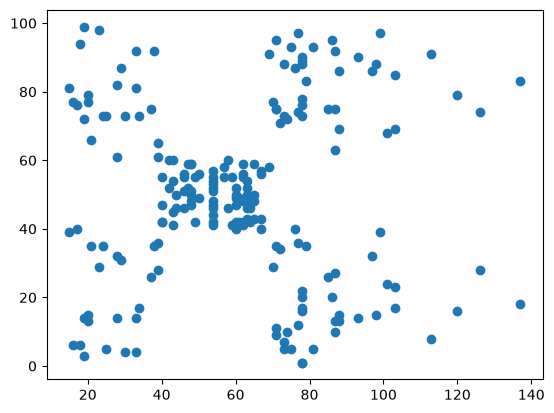

In [6]:
import matplotlib.pyplot as plt
plt.scatter(x, y)
plt.show()

## Langkah 7 — Scaling data dan Elbow Method untuk dua fitur

Di tahap ini, data dua fitur disamakan skalanya dengan `MinMaxScaler`. Elbow Method kemudian mencoba jumlah klaster dari 1 sampai 10. Nilai WCSS (*Within-Cluster Sum of Squares*) dari setiap percobaan disimpan, lalu diplot. Titik ketika penurunan WCSS mulai melambat digunakan sebagai petunjuk untuk memilih jumlah klaster.

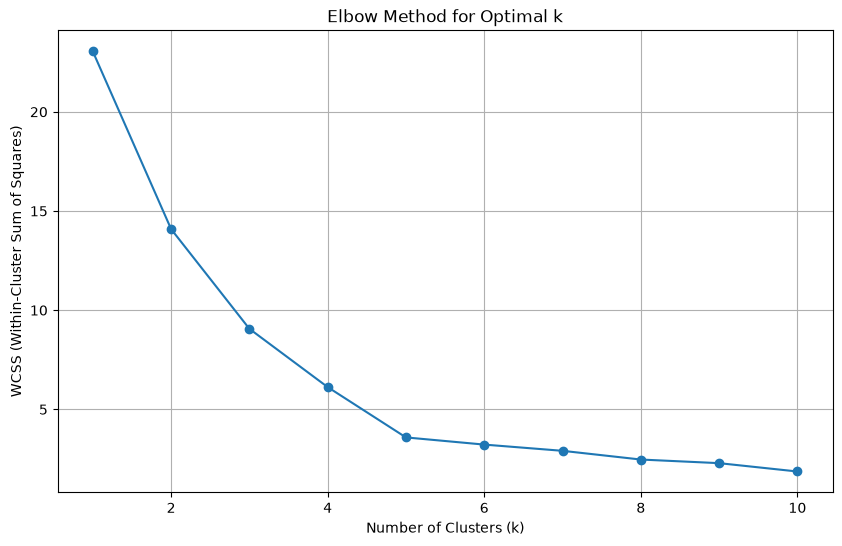

In [7]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# Scaling data dengan MinMaxScaler
scaler = MinMaxScaler()

# Mengambil kolom X (index 3) dan Y (index 4) dari DataFrame
X = pd.DataFrame({'Annual Income (k$)': x, 'Spending Score (1-100)': y})

X_scaled = scaler.fit_transform(X)

# Menentukan jumlah klaster optimal menggunakan Elbow Method
wcss = []
for i in range(1, 11): # Coba k dari 1 sampai 10
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Membuat plot Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

## Langkah 8 — Melihat hasil klaster dua fitur

Sesuai modul, untuk tahap dua fitur digunakan 5 klaster. Model memberi label klaster kepada setiap pelanggan, lalu warna pada scatter plot menunjukkan kelompok masing-masing. Sedikit penyesuaian dari kode modul: model dipasang pada `X_scaled`, konsisten dengan data yang digunakan saat Elbow Method, supaya pemilihan k dan proses klasterisasi memakai skala data yang sama. Titik tetap digambar memakai nilai asli `x` dan `y` agar sumbunya mudah dibaca.

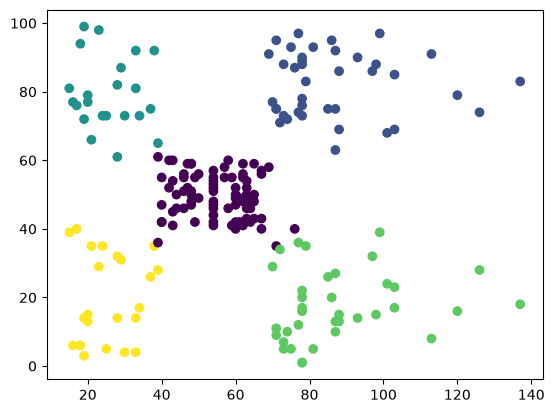

In [8]:
# dari elbow method, nilai k optimal untuk data ini adalah 5
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X_scaled)

# Plot hasil klaster
plt.scatter(x, y, c=kmeans.labels_)
plt.show()

## Langkah 9 — Membuat scatter plot 3D dengan tiga fitur

Selanjutnya digunakan tiga fitur utama: Age, Annual Income, dan Spending Score. Variabel `x`, `y`, dan `z` masing-masing menyimpan ketiga fitur tersebut. Scatter plot 3D membantu melihat persebaran pelanggan berdasarkan tiga dimensi sekaligus. Pada tahap ini, semua titik masih ditampilkan dengan warna yang sama karena klaster belum diterapkan pada plot.

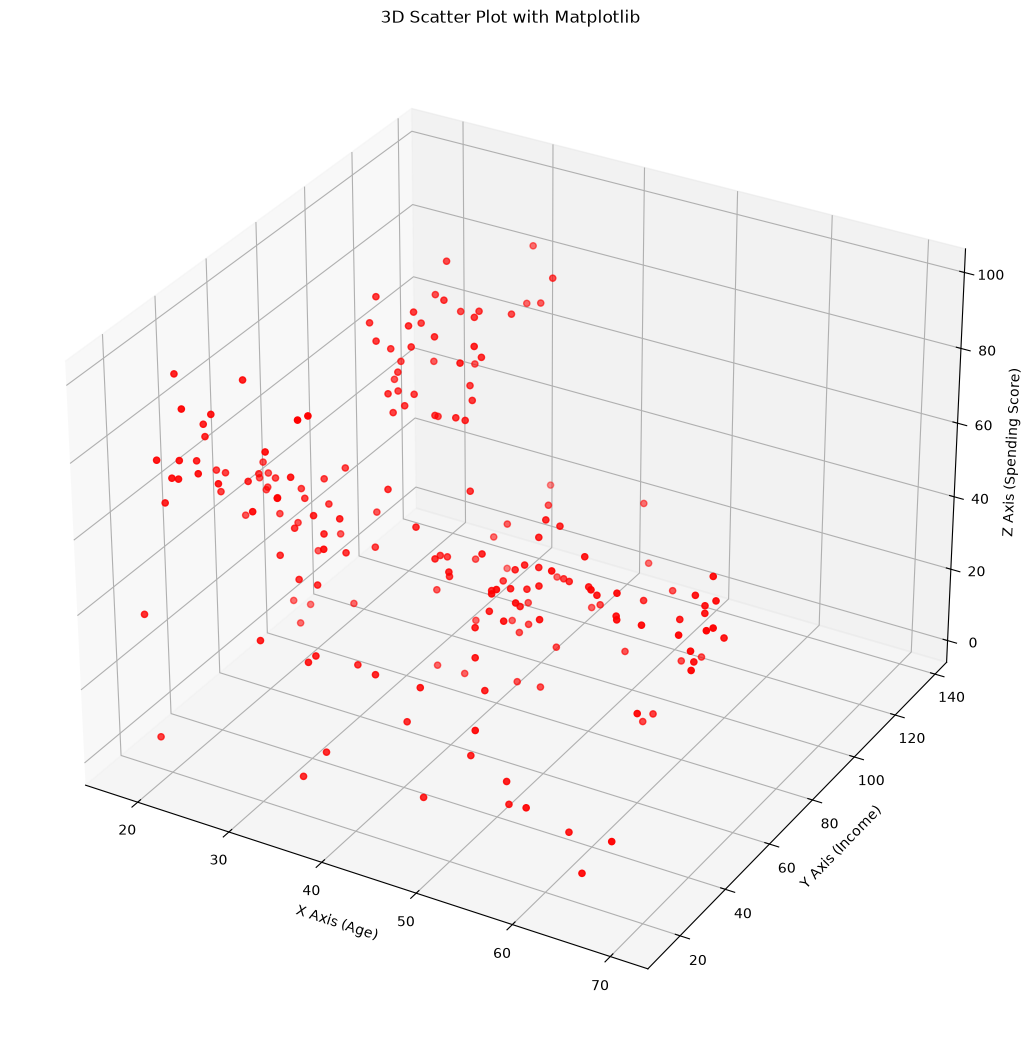

In [9]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Data Age, Annual Income, dan Spending Score
x = df.iloc[:, 2]
y = df.iloc[:, 3]
z = df.iloc[:, 4]

# Membuat plot 3D
fig = plt.figure(figsize=(13, 13))
ax = fig.add_subplot(111, projection='3d')

# Plot data
ax.scatter(x, y, z, c='red', marker='o')

# Label sumbu
ax.set_xlabel('X Axis (Age)')
ax.set_ylabel('Y Axis (Income)')
ax.set_zlabel('Z Axis (Spending Score)')

plt.title('3D Scatter Plot with Matplotlib')
plt.show()

## Langkah 10 — Elbow Method untuk tiga fitur

Data Age, Annual Income, dan Spending Score digabungkan ke dalam satu array. Kemudian ketiganya dinormalisasi dengan `MinMaxScaler` agar skala setiap fitur sebanding. Elbow Method dijalankan lagi untuk nilai k dari 1 sampai 10, lalu WCSS diplot untuk membantu menentukan jumlah klaster pada analisis tiga fitur.

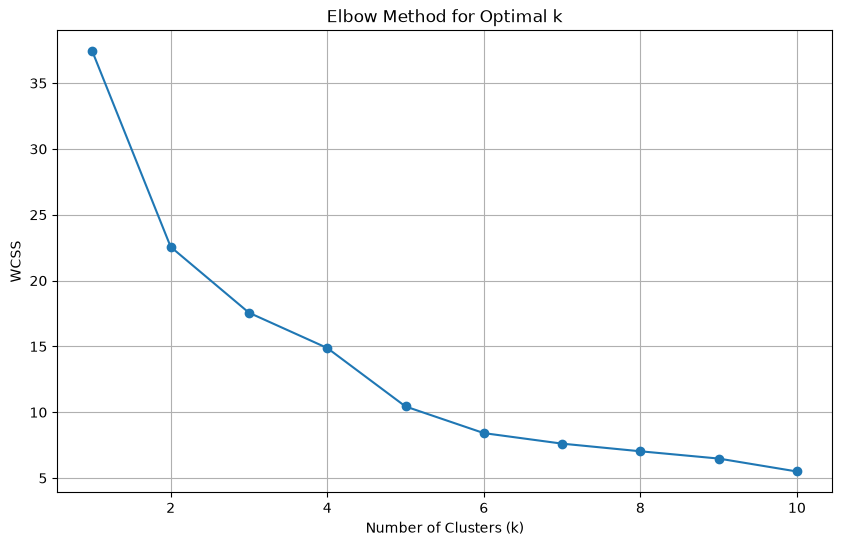

In [10]:
# Menggabungkan data X, Y, Z menjadi array untuk clustering
X = np.array(list(zip(x, y, z)))

# Scaling data dengan MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Menentukan jumlah klaster optimal dengan Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Visualisasi Elbow Method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

## Langkah 11 — Klasterisasi 3D menggunakan K-Means

Sesuai modul, tahap tiga fitur menggunakan 6 klaster. Hasil label klaster ditambahkan ke kolom `Cluster` pada DataFrame. Kode disesuaikan sedikit agar `fit_predict()` menggunakan `X_scaled`, sama seperti pada Elbow Method. Sementara itu, visualisasi tetap memakai nilai asli Age, Annual Income, dan Spending Score, dengan warna yang berbeda untuk menunjukkan klaster.

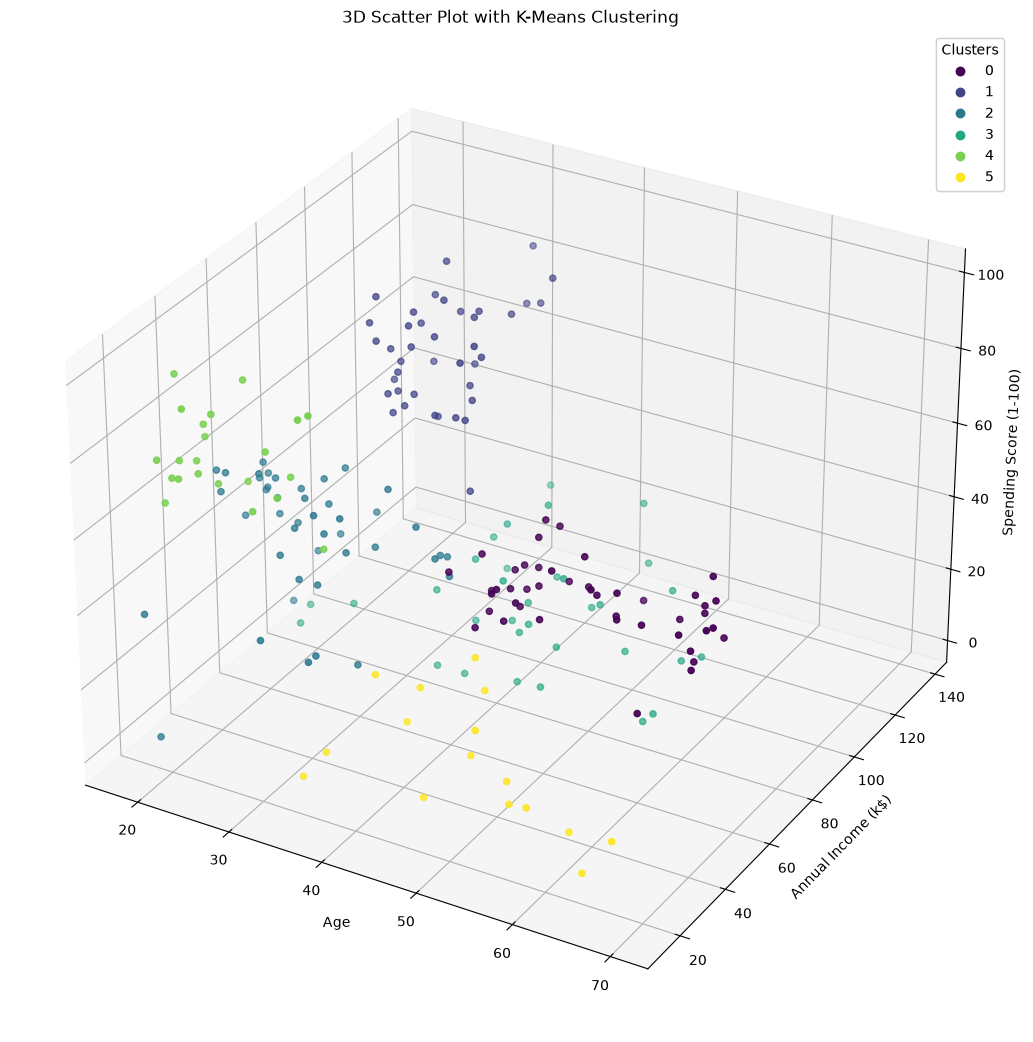

In [12]:
# Pilih k optimal setelah melihat Elbow
kmeans = KMeans(n_clusters=6, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

# Menambahkan hasil klaster ke DataFrame
df['Cluster'] = clusters

# Visualisasi 3D Hasil K-Means

# Plot data dengan warna berdasarkan klaster
fig = plt.figure(figsize=(13, 13))
ax = fig.add_subplot(111, projection='3d')

# Plot setiap titik dengan warna sesuai klaster
scatter = ax.scatter(x, y, z, c=clusters, cmap='viridis', marker='o')

# Label sumbu
ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score (1-100)')

# Menampilkan legenda klaster
legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend1)

plt.title('3D Scatter Plot with K-Means Clustering')
plt.show()